# 8. Round 2, Test B (pre-registered): occupations inside the same industry

**Question:** Within the same industry, did more AI-exposed occupations lose ground after 2023?

**How to use:** Run All. It shows the saved results in seconds. To recompute from the data, set `RUN = True` (about 10 minutes; needs the `data/` folder, which isn't in the public repo).

In [1]:
from _nb import *

RUN = False
if RUN:
    run("event_study_occupation")


## How it works

- **576 cells** = occupation group × industry sector, CPS, yearly 2011–2026.
- **Industry-by-year fixed effects:** anything that hit an industry in a year (rates, the pandemic boom, tax rules)
  cancels out. Only differences *between jobs inside the same industry* are left.
- Same headline, power check, pre-trend check and fake date as Test A, plus an **age version**: do young workers in
  exposed jobs fall more than older workers in the same jobs?

## Results

In [2]:
r = results("event_study_occupation")
row = lambda d: {"Δ (top vs bottom quartile)": pct(d["est"]), "95% CI": ci(d["ci95"]), "p": round(d["p"], 3)}
names = {"primary": "Primary", "fake_2016": "Placebo: fake 2016 date",
         "drop_computer_occupations": "Without computer jobs", "drop_info_professional": "Without tech-heavy sectors",
         "own_trend_removed": "Each cell's own trend removed"}
t = {label: row(r[k]["delta_top_vs_bottom_quartile"]) | {"P(below 0)": pct(r[k]["prob_below_zero"], False),
                                                         "pre-trend p": round(r[k]["pretrend"]["p"], 2)}
     for k, label in names.items()}
a = r["age"]
t["Age version: young (22–27) minus older (35–65)"] = row(a["delta_young_minus_old_top_vs_bottom_quartile"]) | {
    "P(below 0)": pct(a["prob_below_zero"], False), "pre-trend p": round(a["pretrend"]["p"], 2)}
pd.DataFrame(t).T

,Δ (top vs bottom quartile),95% CI,p,P(below 0),pre-trend p
Primary,+0.3%,"[-5.6, +6.1]",0.932,46.6%,0.23
Placebo: fake 2016 date,+0.1%,"[-3.6, +3.9]",0.954,47.7%,0.2
Without computer jobs,-0.4%,"[-6.6, +5.8]",0.901,55.0%,0.3
Without tech-heavy sectors,-0.0%,"[-6.2, +6.2]",0.995,50.3%,0.21
Each cell's own trend removed,-1.9%,"[-8.0, +4.2]",0.535,73.3%,0.1
Age version: young (22–27) minus older (35–65),-6.3%,"[-15.5, +2.9]",0.178,91.3%,0.18


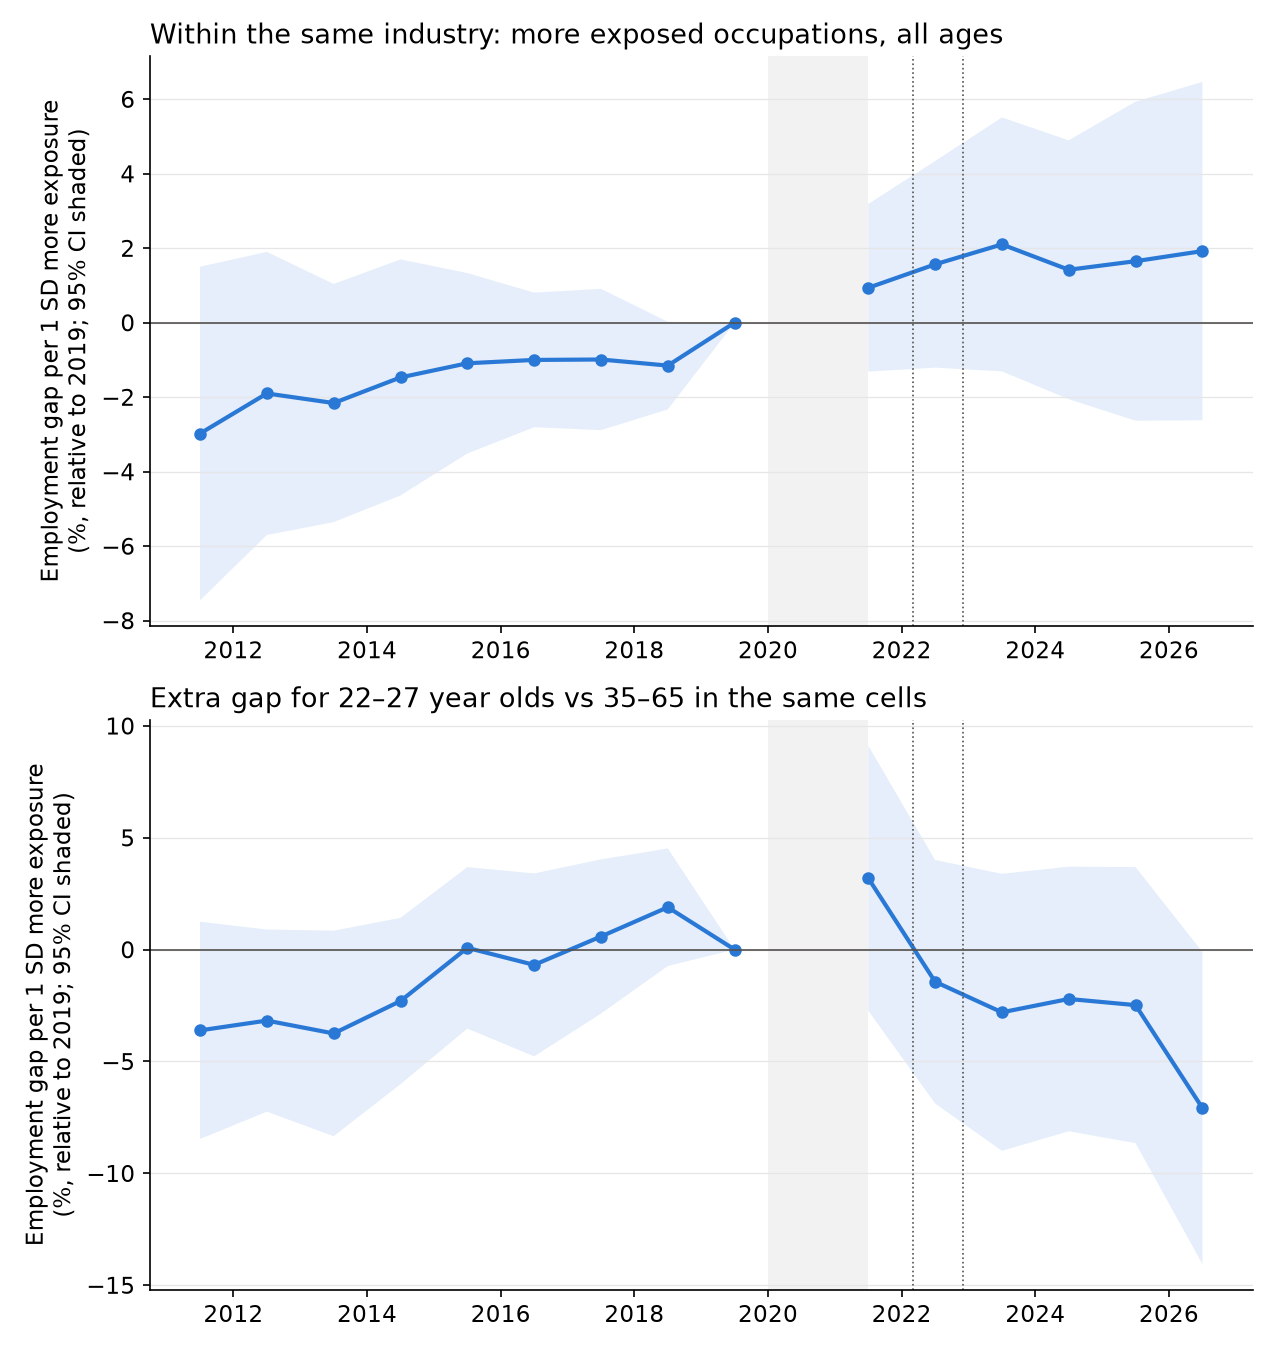

In [3]:
figure("fig_event_study_occupation")

## What it means

**The clearest result in the project.** Inside the same industries, AI-exposed occupations have **not** lost
ground since ChatGPT (+0.3%, 95% CI about ±6%), and the test passed every check. So the industry-level slide in Test
A looks like whole industries shrinking, not exposed jobs being replaced. **The open question:** young workers in
exposed jobs fell 6.3% more than older workers in the same jobs (91% likely below zero, p = 0.18), mostly in 2026. That matches
Stanford's direction but needs bigger data (the ACS) to confirm.

---
Code: `scripts/event_study_occupation.py` · All results: `docs/SCORECARD.md` · Every decision: `docs/DECISIONS.md` · The whole story: `README.md`